In [ ]:
import pandas as pd #import pandas for data manipulation

In [ ]:
from pathlib import Path
file_path = Path("../../../trainingdata/sales_dataset.csv").resolve().parent #locate the dataset file in training data folder

In [ ]:
df = pd.read_csv(file_path / "sales_dataset.csv")
df.head() #load the dataset and display the first 5 rows of the dataset

,marketing_budget(thousands),actual_sales(millions)
0,187.86,12.14
1,138.13,12.33
2,177.89,8.41
3,181.13,8.90
4,151.50,12.57


In [7]:
x = df['marketing_budget(thousands)']
y = df['actual_sales(millions)']

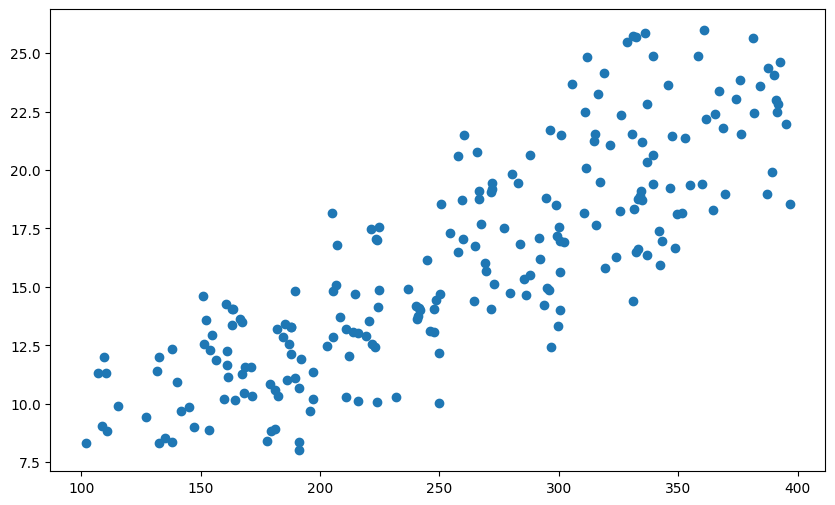

In [9]:
import matplotlib.pyplot as plt #import matplotlib for data visualization
plt.figure(figsize=(10, 6))
plt.scatter(x , y)
plt.show()
#check if there is a linear relationship between the marketing budget and actual sales

In [48]:
from sklearn.linear_model import LinearRegression #import linear model from scikit learn
from sklearn.model_selection import train_test_split #import train test split from scikit learn

In [49]:
X_train , X_test, y_train, y_test = train_test_split(x , y, test_size=0.3, random_state=42) #split the dataset into training and testing data

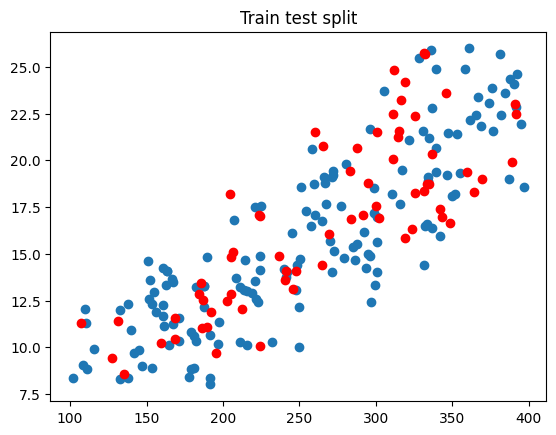

In [41]:
plt.scatter(X_train , y_train)
plt.scatter(X_test, y_test , color='r')
plt.title("Train test split")
plt.show()

In [ ]:
lr = LinearRegression() #create an instance of the linear regression model

lr.fit(X_train.values.reshape(-1, 1), y_train.values) #fit the model to the training data

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


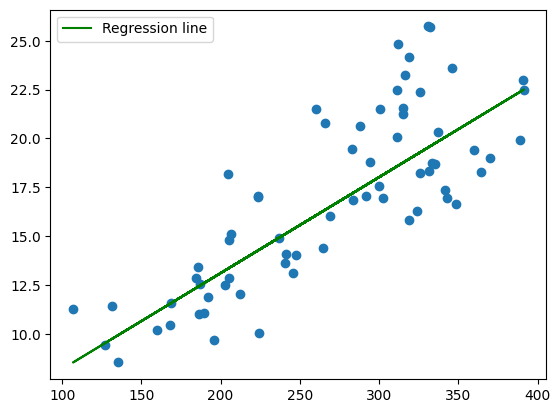

In [51]:
prediction = lr.predict(X_test.values.reshape(-1, 1)) #make predictions on the test data

plt.plot(X_test, prediction, label = 'Regression line', color='g') #plot the regression line
plt.legend()
plt.scatter(X_test , y_test)

In [52]:
import numpy as np
lr.predict(np.array([[215]])) #predict the actual sales for a marketing budget of 100 thousands

array([13.84786816])

In [53]:
score = lr.score(X_test.values.reshape(-1, 1), y_test.values) #calculate the variance with r^2
print(score)

0.6379005570407199
